In [25]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/sales_data.csv")

print("Dataset loaded successfully!")
print("Dataset dimensions:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset dimensions: (10, 6)


,order_id,product,category,units_sold,unit_price,region
0,1001,Mouse,Electronics,3,799,North
1,1002,Notebook,Stationery,10,60,East
2,1003,Desk Lamp,Home,2,1299,South
3,1004,Keyboard,Electronics,2,1499,West
4,1005,Pen Set,Stationery,8,120,North


In [33]:
print("1. Dataset information:")
df.info()

print("\n2. Missing values in each column:")
print(df.isnull().sum())

print("\n3. Duplicate rows:")
print(df.duplicated().sum())

print("\n4. Statistical summary:")
display(df.describe())

df["revenue"] = df["units_sold"] * df["unit_price"]

total_revenue = df["revenue"].sum()

print(f"Total sales revenue: ₹{total_revenue:,.2f}")

product_revenue = (
    df.groupby("product")["revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("\nRevenue by product:")
display(product_revenue)

1. Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   order_id    10 non-null     int64
 1   product     10 non-null     str  
 2   category    10 non-null     str  
 3   units_sold  10 non-null     int64
 4   unit_price  10 non-null     int64
 5   region      10 non-null     str  
 6   revenue     10 non-null     int64
dtypes: int64(4), str(3)
memory usage: 692.0 bytes

2. Missing values in each column:
order_id      0
product       0
category      0
units_sold    0
unit_price    0
region        0
revenue       0
dtype: int64

3. Duplicate rows:
0

4. Statistical summary:


,order_id,units_sold,unit_price,revenue
count,10.00000,10.000000,10.000000,10.000000
mean,1005.50000,5.000000,783.300000,2166.000000
std,3.02765,3.741657,595.428706,1365.662558
min,1001.00000,1.000000,60.000000,600.000000
25%,1003.25000,2.250000,189.750000,1044.750000
50%,1005.50000,3.500000,799.000000,1996.500000
75%,1007.75000,7.250000,1299.000000,2898.000000
max,1010.00000,12.000000,1499.000000,4497.000000


Total sales revenue: ₹21,660.00

Revenue by product:


product
Keyboard        7495
Mouse           6392
Desk Lamp       3897
Water Bottle    1596
Notebook        1320
Pen Set          960
Name: revenue, dtype: int64

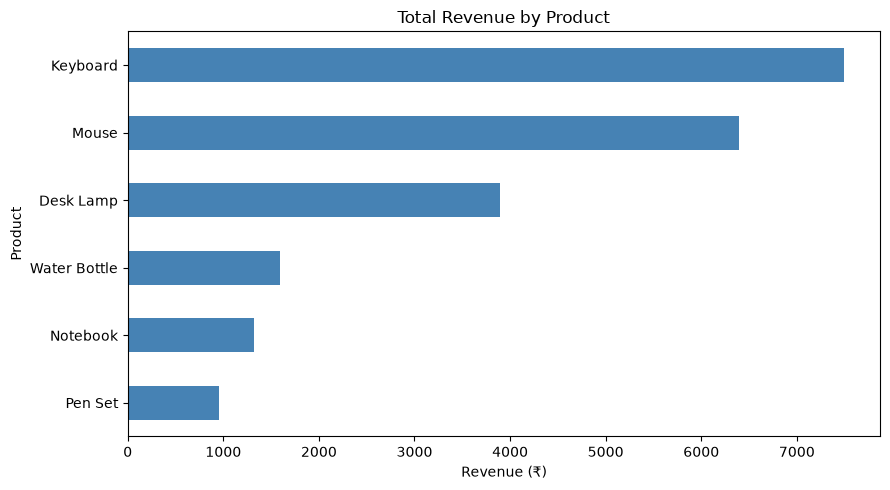

Chart saved successfully!


In [34]:
import matplotlib.pyplot as plt
df["revenue"] = df["units_sold"] * df["unit_price"]
product_revenue = (
    df.groupby("product")["revenue"]
    .sum()
    .sort_values()
)
plt.figure(figsize=(9, 5))
product_revenue.plot(kind="barh", color="steelblue")

plt.title("Total Revenue by Product")
plt.xlabel("Revenue (₹)")
plt.ylabel("Product")
plt.tight_layout()

plt.savefig("../outputs/revenue_by_product.png", dpi=300)
plt.show()

print("Chart saved successfully!")

In [35]:
clean_df = df.copy()
clean_df = clean_df.drop_duplicates()
print("Missing values:")
print(clean_df.isnull().sum())
print("\nInvalid units sold:",
      (clean_df["units_sold"] <= 0).sum())

print("Invalid unit prices:",
      (clean_df["unit_price"] < 0).sum())
print("Duplicate order IDs:",
      clean_df["order_id"].duplicated().sum())

print("\nCleaned dataset shape:", clean_df.shape)

Missing values:
order_id      0
product       0
category      0
units_sold    0
unit_price    0
region        0
revenue       0
dtype: int64

Invalid units sold: 0
Invalid unit prices: 0
Duplicate order IDs: 0

Cleaned dataset shape: (10, 7)


In [36]:
clean_df.to_csv(
    "../outputs/cleaned_sales_data.csv",
    index=False
)
print("Cleaned dataset saved successfully!")
print("Saved 10 records.")

Cleaned dataset saved successfully!
Saved 10 records.


In [37]:
clean_df["revenue"] = (
    clean_df["units_sold"] * clean_df["unit_price"]
)
category_revenue = (
    clean_df.groupby("category")["revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("Revenue by Category:")
display(category_revenue)

Revenue by Category:


category
Electronics    13887
Home            5493
Stationery      2280
Name: revenue, dtype: int64

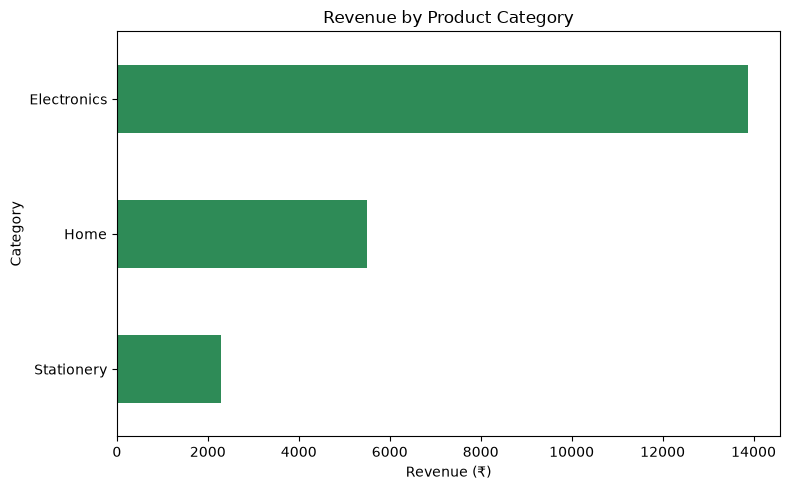

Category chart saved successfully!


In [38]:
import matplotlib.pyplot as plt

category_revenue = (
    clean_df.groupby("category")["revenue"]
    .sum()
    .sort_values(ascending=True)
)

plt.figure(figsize=(8, 5))
category_revenue.plot(kind="barh", color="seagreen")

plt.title("Revenue by Product Category")
plt.xlabel("Revenue (₹)")
plt.ylabel("Category")
plt.tight_layout()

plt.savefig("../outputs/revenue_by_category.png", dpi=300)
plt.show()

print("Category chart saved successfully!")

In [39]:



print("CODEVEDX - Project 1: Data Analysis with Python")
print("=" * 50)
print("Total orders:", len(clean_df))
print("Total revenue: ₹{:,.2f}".format(clean_df["revenue"].sum()))
print("Unique products:", clean_df["product"].nunique())
print("Product categories:", clean_df["category"].nunique())
print("Regions covered:", clean_df["region"].nunique())

print("\nTop revenue-generating product:")
print(clean_df.groupby("product")["revenue"].sum().idxmax())

print("\nTop revenue-generating category:")
print(clean_df.groupby("category")["revenue"].sum().idxmax())

CODEVEDX - Project 1: Data Analysis with Python
Total orders: 10
Total revenue: ₹21,660.00
Unique products: 6
Product categories: 3
Regions covered: 4

Top revenue-generating product:
Keyboard

Top revenue-generating category:
Electronics
